# Practical No. 05: Image Generation Using Pretrained Stable Diffusion
## Theme: Nature and Environment
**Submitted By:**

| Sr. No. | Name | PRN |
|---|---|---|
| 1 | Snehal Pagare Ranjit | 202502110003


**Aim:** To implement a pretrained Stable Diffusion model using the Hugging Face Diffusers library to generate images from text prompts, and to analyze the impact of inference steps, guidance scale and sampling methods (schedulers) on image quality.

**Environment:** Google Colab (Runtime > Change runtime type > T4 GPU)

## 1. Install libraries

In [1]:
!pip install -q --upgrade diffusers transformers accelerate safetensors matplotlib pandas

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires pandas==2.2.3, but you have pandas 3.1.0 which is incompatible.


## 2. Import libraries and check GPU

In [2]:
import os, time, torch
import pandas as pd
import matplotlib.pyplot as plt
from diffusers import (DiffusionPipeline, PNDMScheduler, DDIMScheduler,
                       EulerDiscreteScheduler, EulerAncestralDiscreteScheduler,
                       DPMSolverMultistepScheduler)

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
DTYPE = torch.float16 if DEVICE == "cuda" else torch.float32
print("CUDA available:", torch.cuda.is_available())
if DEVICE == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))
SEED = 42
OUT = "results"
os.makedirs(OUT, exist_ok=True)

/usr/local/lib/python3.13/dist-packages/pandas/core/arrays/masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (


CUDA available: False


## 3. Load the pretrained model
`segmind/tiny-sd` is a small, fast Stable Diffusion model. For higher quality, change `MODEL_ID` to `"stable-diffusion-v1-5/stable-diffusion-v1-5"`.

In [3]:
MODEL_ID = "segmind/tiny-sd"
pipe = DiffusionPipeline.from_pretrained(MODEL_ID, torch_dtype=DTYPE).to(DEVICE)
ORIG_CONFIG = pipe.scheduler.config   # keep the original config for switching schedulers
print("Loaded:", MODEL_ID, "| default scheduler:", type(pipe.scheduler).__name__)

/usr/local/lib/python3.13/dist-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)


model_index.json:   0%|          | 0.00/584 [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 12 files:   0%|          | 0/12 [00:00<?, ?it/s]

Loading pipeline components...:   0%|          | 0/5 [00:00<?, ?it/s]

An error occurred while trying to fetch /root/.cache/huggingface/hub/models--segmind--tiny-sd/snapshots/cad0bd7495fa6c4bcca01b19a723dc91627fe84f/vae: Error no file named diffusion_pytorch_model.safetensors found in directory /root/.cache/huggingface/hub/models--segmind--tiny-sd/snapshots/cad0bd7495fa6c4bcca01b19a723dc91627fe84f/vae.
Defaulting to unsafe serialization. Pass `allow_pickle=False` to raise an error instead.
An error occurred while trying to fetch /root/.cache/huggingface/hub/models--segmind--tiny-sd/snapshots/cad0bd7495fa6c4bcca01b19a723dc91627fe84f/unet: Error no file named diffusion_pytorch_model.safetensors found in directory /root/.cache/huggingface/hub/models--segmind--tiny-sd/snapshots/cad0bd7495fa6c4bcca01b19a723dc91627fe84f/unet.
Defaulting to unsafe serialization. Pass `allow_pickle=False` to raise an error instead.


Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

Loaded: segmind/tiny-sd | default scheduler: DPMSolverMultistepScheduler


## 4. Prompt and helper function

In [4]:
PROMPT = ("A photorealistic restored forest ecosystem in the Western Ghats of India, "
          "lush green trees, a clear river winding between mossy rocks, soft morning mist, "
          "sunbeams through the canopy, natural colors, highly detailed environmental photography")

NEGATIVE_PROMPT = ("blurry, low quality, low resolution, text, watermark, logo, oversaturated, "
                   "distorted trees, unrealistic objects")

def generate(prompt, steps=30, guidance=7.5, seed=SEED):
    gen = torch.Generator(device=DEVICE).manual_seed(seed)
    t = time.perf_counter()
    img = pipe(prompt, negative_prompt=NEGATIVE_PROMPT, num_inference_steps=steps,
               guidance_scale=guidance, generator=gen).images[0]
    if DEVICE == "cuda": torch.cuda.synchronize()
    return img, time.perf_counter() - t

def set_scheduler(cls):
    pipe.scheduler = cls.from_config(ORIG_CONFIG)

## 5. Baseline image (30 steps, guidance 7.5)

  0%|          | 0/30 [00:00<?, ?it/s]

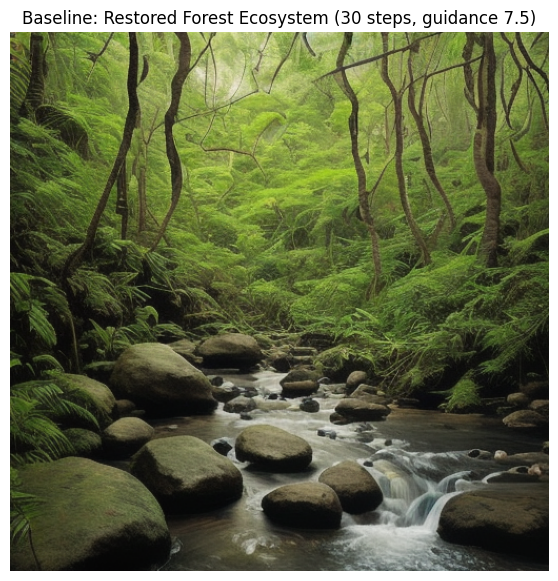

Time: 498.62 s


In [5]:
set_scheduler(DPMSolverMultistepScheduler)
img, sec = generate(PROMPT, 30, 7.5)
img.save(f"{OUT}/baseline.png")
plt.figure(figsize=(7,7)); plt.imshow(img); plt.axis("off")
plt.title("Baseline: Restored Forest Ecosystem (30 steps, guidance 7.5)"); plt.show()
print(f"Time: {sec:.2f} s")

## 6. Experiment A: Effect of inference steps
Prompt, guidance (7.5), scheduler and seed are fixed; only steps change.

  0%|          | 0/5 [00:00<?, ?it/s]

  0%|          | 0/10 [00:00<?, ?it/s]

  0%|          | 0/20 [00:00<?, ?it/s]

  0%|          | 0/30 [00:00<?, ?it/s]

  0%|          | 0/50 [00:00<?, ?it/s]

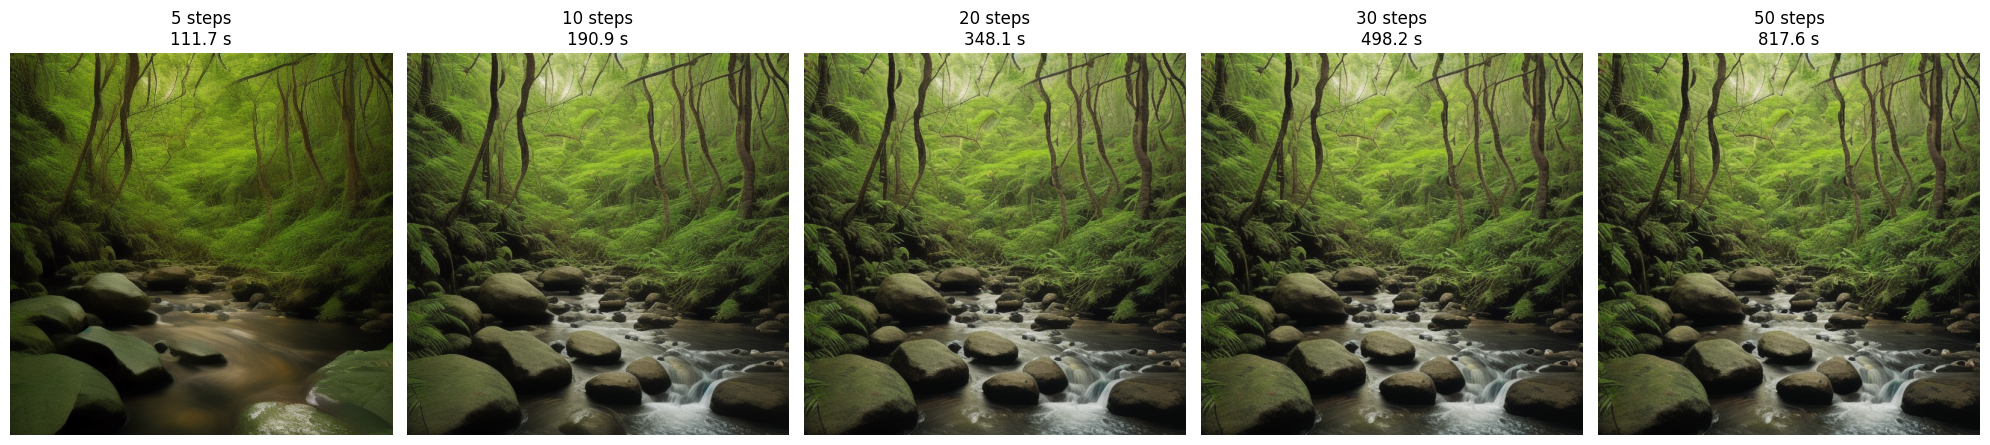

,experiment,setting,seconds
0,steps,5,111.68
1,steps,10,190.94
2,steps,20,348.12
3,steps,30,498.19
4,steps,50,817.61


In [6]:
set_scheduler(DPMSolverMultistepScheduler)
steps_list = [5, 10, 20, 30, 50]
rows = []
fig, axes = plt.subplots(1, len(steps_list), figsize=(4*len(steps_list), 5))
for ax, n in zip(axes, steps_list):
    img, sec = generate(PROMPT, steps=n, guidance=7.5)
    img.save(f"{OUT}/steps_{n}.png")
    ax.imshow(img); ax.axis("off"); ax.set_title(f"{n} steps\n{sec:.1f} s")
    rows.append({"experiment":"steps","setting":n,"seconds":round(sec,2)})
plt.tight_layout(); plt.show()
steps_df = pd.DataFrame(rows); steps_df

### Observation: Inference steps
- At very low steps (5-10) the image is generated fastest but looks rough, with unclear shapes and little detail.
- At 20-30 steps the trees, river and mist become clear and well-defined.
- At 50 steps the image is only slightly different from 30 steps, but generation takes noticeably longer.
- Generation time increases roughly in proportion to the number of steps (see the table above).

**Conclusion:** Around 25-30 inference steps gives a good balance between image quality and generation time.

## 7. Experiment B: Effect of guidance scale
Prompt, steps (30), scheduler and seed are fixed; only guidance changes.

  0%|          | 0/30 [00:00<?, ?it/s]

  0%|          | 0/30 [00:00<?, ?it/s]

  0%|          | 0/30 [00:00<?, ?it/s]

  0%|          | 0/30 [00:00<?, ?it/s]

  0%|          | 0/30 [00:00<?, ?it/s]

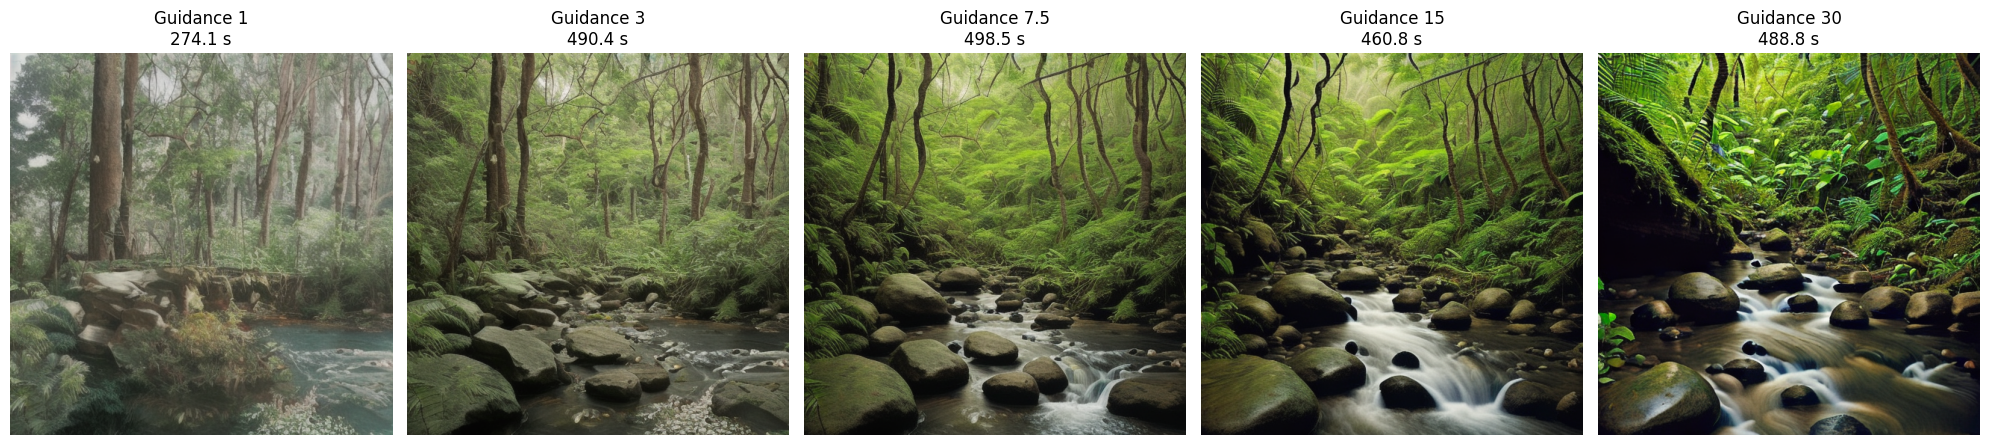

,experiment,setting,seconds
0,guidance,1.0,274.10
1,guidance,3.0,490.37
2,guidance,7.5,498.47
3,guidance,15.0,460.84
4,guidance,30.0,488.82


In [7]:
set_scheduler(DPMSolverMultistepScheduler)
guidance_list = [1, 3, 7.5, 15, 30]
rows = []
fig, axes = plt.subplots(1, len(guidance_list), figsize=(4*len(guidance_list), 5))
for ax, g in zip(axes, guidance_list):
    img, sec = generate(PROMPT, steps=30, guidance=g)
    img.save(f"{OUT}/guidance_{str(g).replace('.','_')}.png")
    ax.imshow(img); ax.axis("off"); ax.set_title(f"Guidance {g}\n{sec:.1f} s")
    rows.append({"experiment":"guidance","setting":g,"seconds":round(sec,2)})
plt.tight_layout(); plt.show()
guid_df = pd.DataFrame(rows); guid_df

### Observation: Guidance scale
- At low guidance (1 and 3) the model follows the prompt weakly, so the image is less related to the text and often looks vague.
- At 7.5 the image follows the prompt well and still looks natural.
- At high guidance (15 and 30) the colours become over-saturated and harsh, and visual artifacts appear.

**Conclusion:** A guidance scale of about 7.5 is the best balance between following the prompt and image quality.

## 8. Experiment C: Sampling methods (schedulers)
Prompt, steps (30), guidance (7.5) and seed are fixed; only the scheduler changes.

  0%|          | 0/30 [00:00<?, ?it/s]

  0%|          | 0/30 [00:00<?, ?it/s]

  0%|          | 0/30 [00:00<?, ?it/s]

  0%|          | 0/30 [00:00<?, ?it/s]

  0%|          | 0/30 [00:00<?, ?it/s]

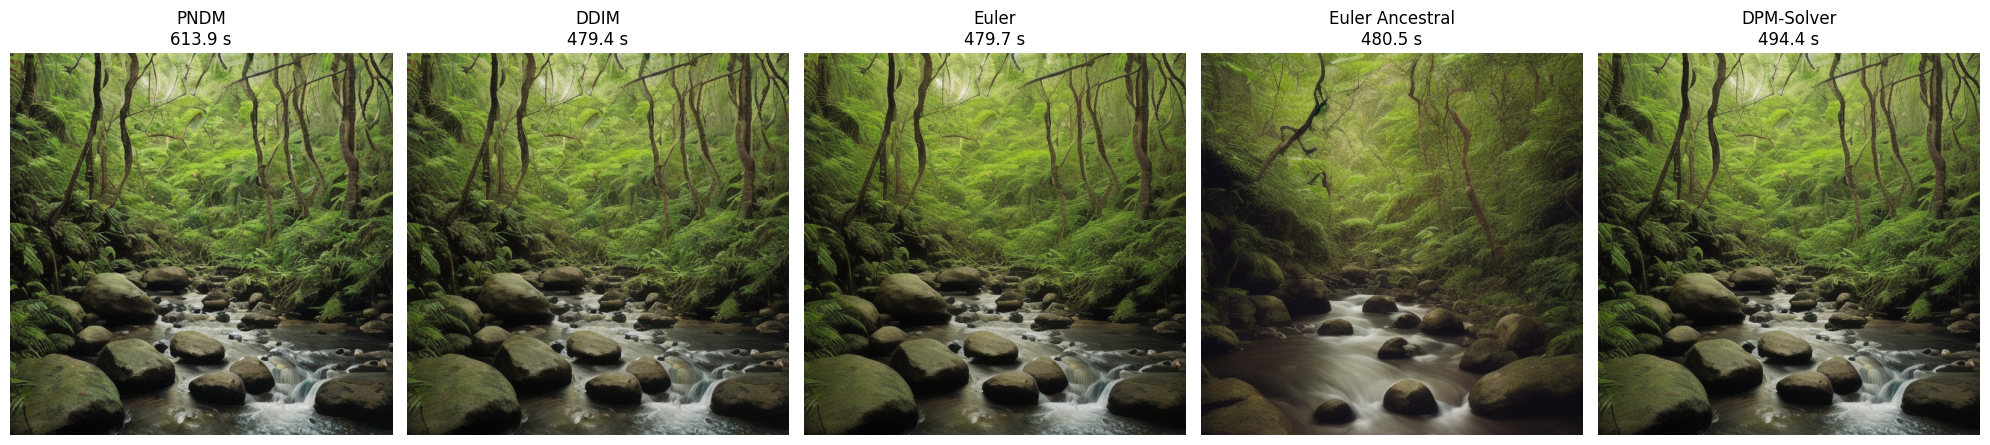

,experiment,setting,seconds
0,scheduler,PNDM,613.88
1,scheduler,DDIM,479.35
2,scheduler,Euler,479.66
3,scheduler,Euler Ancestral,480.48
4,scheduler,DPM-Solver,494.44


In [8]:
schedulers = {"PNDM": PNDMScheduler, "DDIM": DDIMScheduler, "Euler": EulerDiscreteScheduler,
              "Euler Ancestral": EulerAncestralDiscreteScheduler, "DPM-Solver": DPMSolverMultistepScheduler}
rows = []
fig, axes = plt.subplots(1, len(schedulers), figsize=(4*len(schedulers), 5))
for ax, (name, cls) in zip(axes, schedulers.items()):
    set_scheduler(cls)
    img, sec = generate(PROMPT, steps=30, guidance=7.5)
    img.save(f"{OUT}/scheduler_{name.lower().replace(' ','_')}.png")
    ax.imshow(img); ax.axis("off"); ax.set_title(f"{name}\n{sec:.1f} s")
    rows.append({"experiment":"scheduler","setting":name,"seconds":round(sec,2)})
plt.tight_layout(); plt.show()
sched_df = pd.DataFrame(rows); sched_df

### Observation: Sampling methods
- All five schedulers (PNDM, DDIM, Euler, Euler Ancestral, DPM-Solver) used the same prompt, seed, steps and guidance, but produced slightly different images in layout, sharpness and colour.
- Euler Ancestral adds random noise at each step, so its result differs the most from the others.
- DDIM, Euler and DPM-Solver give smoother and more consistent results.
- DPM-Solver gives good quality with a small number of steps.

**Conclusion:** DPM-Solver is a good choice because it gives good quality efficiently. Different schedulers change the image even when all other settings are the same.

## 9. Additional nature and environment prompts

  0%|          | 0/30 [00:00<?, ?it/s]

  0%|          | 0/30 [00:00<?, ?it/s]

  0%|          | 0/30 [00:00<?, ?it/s]

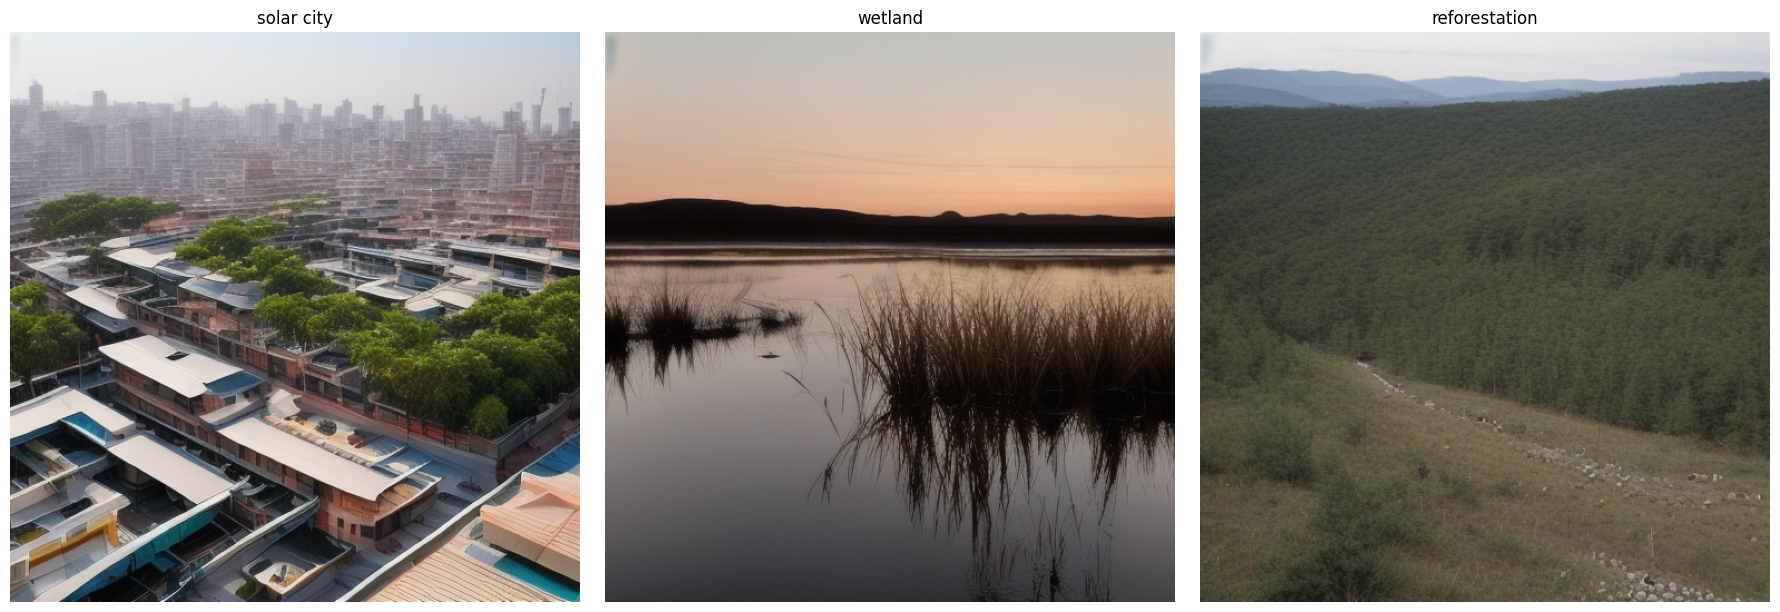

In [12]:
set_scheduler(DPMSolverMultistepScheduler)
prompts = {
  "solar_city": "A photorealistic sustainable Indian city with rooftop solar panels, green roofs, tree-lined streets, bicycles, clean public transport, clear morning light, realistic architectural environmental photography",
  "wetland": "A protected wetland ecosystem at sunrise, shallow reflective water, reeds, native birds in the distance, rich biodiversity, soft mist, realistic nature photography",
  "reforestation": "A reforestation project on a hillside, young native trees planted in organized sections blending into a mature green forest, volunteers small in the distance, hopeful natural lighting, documentary photography",
}
fig, axes = plt.subplots(1, len(prompts), figsize=(6*len(prompts), 6))
for ax, (k, p) in zip(axes, prompts.items()):
    img, sec = generate(p, 30, 7.5)
    img.save(f"{OUT}/prompt_{k}.png")
    ax.imshow(img); ax.axis("off"); ax.set_title(k.replace("_"," "))
plt.tight_layout(); plt.show()

In [11]:
pd.concat([steps_df, guid_df, sched_df]).to_csv(f"{OUT}/timings.csv", index=False)
import shutil; shutil.make_archive("results", "zip", OUT)
print("Saved results.zip")

Saved results.zip


## 11. Result and Conclusion
**Result:** A pretrained Stable Diffusion model was used through Hugging Face Diffusers to generate nature and environment images from text prompts, and the effect of inference steps, guidance scale and sampling method on the output was compared.

**Conclusion:** Increasing inference steps improves detail but increases generation time, and about 25-30 steps is enough. A guidance scale near 7.5 follows the prompt well without artifacts, while very high values spoil the image. Different schedulers give slightly different images, and DPM-Solver is efficient. The final image depends on the prompt, steps, guidance scale, scheduler and the model used.

**Github link:** https://github.com/snehalpagare272005-jpg/Stable-Diffusion-Text-to-Image/blob/main/Topic_Modeling_NLP_Cleaned%20(1).ipynb